# T07 · Logistic Regression (Probability · Threshold · Coefficients / Odds ratio · Evaluation · ROC)

**ใช้เมื่อโจทย์ถาม:** ทำนายความน่าจะเป็น (predict_proba) · เปลี่ยน threshold (0.5 → 0.3) · confusion matrix แต่ละ threshold ·
สมการ logit / sigmoid · ตีความ coefficient / **odds ratio** $e^{b}$ · คำนวณ p ด้วยมือ · ROC/AUC · เทียบ baseline · tune C

| ขั้น | ทำอะไร |
|---|---|
| 1 | แก้ **⚙️ CONFIG** — `TARGET`, `POS_LABEL`, `THRESHOLD`, `NEW_DATA` |
| 2 | Run All · coefficient §3 · ตาราง threshold §5 |

In [1]:
# ════════ ⚙️ CONFIG — แก้ cell นี้ให้ตรงโจทย์ ════════
DATA_PATH = "../practice/data/p5_pima_diabetes.csv"
TARGET    = "diabetes"
POS_LABEL = 1                # คลาสที่สนใจ (= 1)
ID_COL    = None
DROP_COLS = []
FEATURES  = None             # list feature ที่โจทย์ให้ใช้ · None = ทั้งหมด
ZERO_AS_MISSING = ["glucose", "blood_pressure", "skin_thickness", "insulin", "bmi"]   # ข้อมูลอื่นใส่ []
THRESHOLD = 0.3              # threshold ที่โจทย์ให้ลอง (เทียบกับ 0.5)
THRESHOLDS = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
NEW_DATA  = {"pregnancies": 2, "glucose": 150, "blood_pressure": 70, "skin_thickness": 30,
             "insulin": 100, "bmi": 32.0, "pedigree": 0.5, "age": 45}   # None = ข้าม
SCALE     = "standard"
TEST_SIZE, N_FOLDS, SEED = 0.2, 5, 42
MISSING_MARKERS, SHEET, CSV_SEP = ["?", "", " ", "NA"], 0, ","

In [2]:
# ════════ 🔧 IMPORTS + HELPERS — ไม่ต้องแก้ cell นี้ แค่รันหลัง CONFIG ════════
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import (train_test_split, StratifiedKFold, KFold, cross_validate,
                                     cross_val_predict, GridSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (StandardScaler, MinMaxScaler, OneHotEncoder, OrdinalEncoder,
                                   KBinsDiscretizer, LabelEncoder)
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor, NearestNeighbors
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import (DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text)
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, precision_recall_curve, average_precision_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             mean_absolute_error, mean_squared_error, r2_score,
                             silhouette_score, silhouette_samples, davies_bouldin_score)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

# ค่า default ถ้า CONFIG ไม่ได้กำหนดไว้ (กันลืม)
for _name, _val in {"SEED": 42, "N_FOLDS": 5, "TEST_SIZE": 0.2, "TARGET": None, "POS_LABEL": None,
                    "ID_COL": None, "DROP_COLS": [], "MISSING_MARKERS": ["?", "", " ", "NA", "N/A", "null"],
                    "SHEET": 0, "CSV_SEP": ",", "SCALE": "standard"}.items():
    globals().setdefault(_name, _val)


def load_data(path, sheet=None, sep=None, na_values=None):
    """อ่าน .csv / .xlsx / .xls → ตัดช่องว่างหัวคอลัมน์และค่า string → แปลงค่าแฝง ('?', '') เป็น NaN"""
    sheet = SHEET if sheet is None else sheet
    sep = CSV_SEP if sep is None else sep
    na_values = MISSING_MARKERS if na_values is None else na_values
    if str(path).lower().endswith((".xlsx", ".xls")):
        df = pd.read_excel(path, sheet_name=sheet)
    else:
        for enc in ["utf-8-sig", "cp874", "latin1"]:      # utf-8 (ตัด BOM) → ภาษาไทยจาก Excel (cp874) → อื่น ๆ
            try:
                df = pd.read_csv(path, sep=sep, encoding=enc)
                break
            except UnicodeDecodeError:
                continue
        if df.shape[1] == 1 and ";" in str(df.columns[0]):  # ไฟล์คั่นด้วย ; แต่ตั้ง CSV_SEP = ","
            df = pd.read_csv(path, sep=";", encoding=enc)
            print("ℹ️ ไฟล์นี้คั่นด้วย ';' → อ่านใหม่ด้วย sep=';'")
    df.columns = [str(c).strip() for c in df.columns]
    for c in df.columns:
        if not pd.api.types.is_numeric_dtype(df[c]) and not pd.api.types.is_bool_dtype(df[c]):
            df[c] = df[c].map(lambda v: v.strip() if isinstance(v, str) else v)
    df = df.replace(list(na_values), np.nan)
    # คอลัมน์ที่เป็นตัวเลขแต่ถูกอ่านเป็น text (เพราะเคยมี '?') → แปลงกลับเป็นตัวเลข
    for c in df.columns:
        if not pd.api.types.is_numeric_dtype(df[c]) and not pd.api.types.is_bool_dtype(df[c]):
            conv = pd.to_numeric(df[c], errors="coerce")
            if conv.notna().sum() == df[c].notna().sum() and df[c].notna().any():
                df[c] = conv
    print(f"โหลด {path} → {df.shape[0]} แถว × {df.shape[1]} คอลัมน์")
    return df


def check(df, target=None):
    """ตรวจข้อมูลใน 1 คำสั่ง: ขนาด · ชนิด · ค่าว่าง · unique · ตัวอย่างค่า · สัดส่วน target"""
    print("shape:", df.shape, "| แถวซ้ำ:", int(df.duplicated().sum()))
    info = pd.DataFrame({"dtype": df.dtypes.astype(str),
                         "missing": df.isna().sum(),
                         "missing_%": (df.isna().mean() * 100).round(2),
                         "unique": df.nunique(),
                         "example": [df[c].dropna().iloc[0] if df[c].notna().any() else None for c in df]})
    display(info)
    if target is not None and target in df and pd.api.types.is_numeric_dtype(df[target]) and df[target].nunique() > 15:
        print(f"target '{target}' เป็นตัวเลข (regression):")
        display(df[target].describe().to_frame().T)
    elif target is not None and target in df:
        vc = pd.concat([df[target].value_counts(dropna=False), df[target].value_counts(normalize=True, dropna=False).round(4)],
                       axis=1, keys=["count", "ratio"])
        print(f"การกระจายของ target '{target}':")
        display(vc)


def fix_col(df, col, kind="any", i=0):
    """คอลัมน์ที่ตั้งไว้ใน ✏️ ไม่มีในข้อมูลนี้ → เลือกคอลัมน์ชนิดเดียวกันให้ชั่วคราว (Run All ไม่หยุด) — ควรแก้ ✏️ ให้ตรงโจทย์
    kind: "num" = ตัวเลขต่อเนื่อง · "cat" = หมวดหมู่ (ค่าไม่เกิน 20 แบบ) · "any" """
    if col is None or col in df.columns:
        return col
    skip = {ID_COL}
    nums = [c for c in num_cols(df) if c not in skip]
    if kind == "num":
        pool = [c for c in nums if df[c].nunique() > 10] or nums
    elif kind == "cat":
        few = [c for c in df.columns if c not in skip and df[c].nunique() <= 20]
        pool = [c for c in few if c not in nums] + [c for c in few if c in nums]
    else:
        pool = [c for c in df.columns if c not in skip]
    new = pool[min(i, len(pool) - 1)] if pool else None
    print(f"⚠️ ไม่มีคอลัมน์ {col!r} ในข้อมูลนี้ → ใช้ {new!r} แทนชั่วคราว (แก้บรรทัด ✏️ ให้ตรงโจทย์)")
    return new


def num_cols(df):
    return df.select_dtypes(include="number").columns.tolist()


def cat_cols(df):
    return [c for c in df.columns if c not in num_cols(df)]


def make_xy(df, target=None, drop=None, pos_label=None, task="classification"):
    """แยก X / y · ตัด target + DROP_COLS + ID_COL · classification 2 คลาส → y = 1 ถ้าเท่ากับ POS_LABEL"""
    target = TARGET if target is None else target
    drop = DROP_COLS if drop is None else drop
    pos_label = POS_LABEL if pos_label is None else pos_label
    d = df.dropna(subset=[target]).copy()
    removed = [c for c in list(drop) + [ID_COL] if c is not None and c in d.columns and c != target]
    X = d.drop(columns=[target] + removed)
    if task == "regression":
        y = d[target].astype(float)
        print(f"X: {X.shape} | y = '{target}' (ตัวเลข) | ตัดคอลัมน์: {removed}")
        return X, y
    raw = d[target]
    classes = sorted(raw.astype(str).unique())
    if len(classes) == 2:
        pos = str(pos_label) if pos_label is not None else classes[-1]
        if pos not in classes:
            raise ValueError(f"POS_LABEL={pos_label!r} ไม่อยู่ใน {classes} — แก้ใน CONFIG")
        neg = [c for c in classes if c != pos][0]
        y = (raw.astype(str) == pos).astype(int).rename(target)
        print(f"X: {X.shape} | y = '{target}' → 1 = {pos!r} (positive), 0 = {neg!r} | ตัดคอลัมน์: {removed}")
    else:
        y = raw.astype(str)
        print(f"X: {X.shape} | y = '{target}' มี {len(classes)} คลาส {classes} (multiclass → ใช้ macro avg) | ตัดคอลัมน์: {removed}")
    return X, y


def is_binary(y):
    return pd.Series(y).nunique() == 2


def build_prep(X, scale="config", num_impute="median", onehot=True):
    """preprocessing ที่ fit เฉพาะ train (ใส่ใน Pipeline → ไม่ leak)
    ตัวเลข: เติมค่าว่าง (median) → scale ('standard' z-score | 'minmax' 0–1 | None)
    หมวดหมู่: เติมค่าว่าง (ค่าที่พบบ่อยสุด) → one-hot"""
    if scale == "config":                      # ไม่ระบุ → ใช้ SCALE จาก CONFIG · ส่ง None = ไม่ scale
        scale = SCALE
    nums, cats = num_cols(X), cat_cols(X)
    scaler = {"standard": StandardScaler(), "minmax": MinMaxScaler()}.get(scale, "passthrough")
    num_pipe = Pipeline([("impute", SimpleImputer(strategy=num_impute)), ("scale", scaler)])
    enc = OneHotEncoder(handle_unknown="ignore", sparse_output=False) if onehot else \
        OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    cat_pipe = Pipeline([("impute", SimpleImputer(strategy="most_frequent")), ("encode", enc)])
    return ColumnTransformer([("num", num_pipe, nums), ("cat", cat_pipe, cats)],
                             verbose_feature_names_out=False)


def make_pipe(model, X, scale="config", **kw):
    """Pipeline = preprocessing (fit บน train fold เท่านั้น) + model"""
    return Pipeline([("prep", build_prep(X, scale=scale, **kw)), ("model", model)])


def get_cv(task="classification", n=None):
    n = N_FOLDS if n is None else n
    if task == "regression":
        return KFold(n_splits=n, shuffle=True, random_state=SEED)
    return StratifiedKFold(n_splits=n, shuffle=True, random_state=SEED)


def cls_scoring(y):
    if is_binary(y):
        return {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1"}
    return {"accuracy": "accuracy", "precision": "precision_macro", "recall": "recall_macro", "f1": "f1_macro"}


def evaluate(name, model, X, y, cv=None, settings="", train=False):
    """classification ด้วย cross-validation → 1 แถว (ค่าเฉลี่ยทุก fold) ใช้ต่อเป็นตารางเปรียบเทียบ"""
    cv = get_cv() if cv is None else cv
    r = cross_validate(model, X, y, cv=cv, scoring=cls_scoring(y), return_train_score=train)
    row = {"model": name, "settings": settings}
    row.update({m: r[f"test_{m}"].mean() for m in ["accuracy", "precision", "recall", "f1"]})
    row["f1_std"] = r["test_f1"].std()
    if train:
        row["train_accuracy"] = r["train_accuracy"].mean()
    return row


def evaluate_holdout(name, model, X_tr, y_tr, X_te, y_te, settings=""):
    """classification แบบ hold-out: fit บน train → วัดบน test"""
    model.fit(X_tr, y_tr)
    p = model.predict(X_te)
    avg = "binary" if is_binary(y_tr) else "macro"
    return {"model": name, "settings": settings,
            "accuracy": accuracy_score(y_te, p),
            "precision": precision_score(y_te, p, average=avg, zero_division=0),
            "recall": recall_score(y_te, p, average=avg, zero_division=0),
            "f1": f1_score(y_te, p, average=avg, zero_division=0),
            "train_accuracy": accuracy_score(y_tr, model.predict(X_tr))}


def reg_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {"MAE": float(mean_absolute_error(y_true, y_pred)), "MSE": float(mse), "RMSE": float(np.sqrt(mse)),
            "R2": float(r2_score(y_true, y_pred))}


def evaluate_reg(name, model, X, y, cv=None, settings=""):
    """regression ด้วย cross-validation → MAE / MSE / RMSE / R²"""
    cv = get_cv("regression") if cv is None else cv
    r = cross_validate(model, X, y, cv=cv,
                       scoring=["neg_mean_absolute_error", "neg_mean_squared_error", "r2"])
    mse = -r["test_neg_mean_squared_error"].mean()
    return {"model": name, "settings": settings, "MAE": -r["test_neg_mean_absolute_error"].mean(),
            "MSE": mse, "RMSE": np.sqrt(mse), "R2": r["test_r2"].mean()}


def show_cm(y_true, y_pred, title="Confusion matrix"):
    """confusion matrix (แถว = actual, คอลัมน์ = predicted) + classification report"""
    labels = sorted(pd.Series(y_true).unique(), key=str)
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    display(pd.DataFrame(cm, index=[f"actual {l}" for l in labels], columns=[f"pred {l}" for l in labels]))
    if len(labels) == 2:
        tn, fp, fn, tp = cm.ravel()
        print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")
    print(classification_report(y_true, y_pred, digits=4, zero_division=0))
    fig, ax = plt.subplots(figsize=(4, 3.4))
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(title); ax.grid(False); plt.show()


def top_k(grid, n=10):
    """ตารางผล GridSearchCV เรียงจากดีสุด"""
    res = pd.DataFrame(grid.cv_results_)
    cols = [c for c in res if c.startswith("param_")] + \
           [c for c in res if c.startswith("mean_test_") or c.startswith("mean_train_")]
    key = f"mean_test_{grid.refit}" if isinstance(grid.refit, str) else "mean_test_score"
    return res[cols].sort_values(key, ascending=False).head(n).reset_index(drop=True)


def results_table(rows, sort_by=None, ascending=False):
    t = pd.DataFrame(rows)
    if sort_by:
        t = t.sort_values(sort_by, ascending=ascending)
    display(t.reset_index(drop=True))
    return t.reset_index(drop=True)


def say_compare(table, metric="f1", baseline_name=None, higher_is_better=True):
    """พิมพ์ประโยคตีความสำเร็จรูปจากตารางผล (copy ไปใส่คำตอบได้เลย)"""
    t = table.sort_values(metric, ascending=not higher_is_better)
    best = t.iloc[0]
    msg = f"✍️ โมเดลที่ดีที่สุดตาม {metric} คือ {best['model']}"
    if str(best.get("settings", "")):
        msg += f" ({best['settings']})"
    msg += f" ได้ {metric} = {best[metric]:.4f}"
    if baseline_name is not None and baseline_name in set(table["model"]):
        b = table.loc[table["model"] == baseline_name].iloc[0]
        diff = best[metric] - b[metric]
        msg += f" เทียบกับ baseline ({baseline_name}) ที่ได้ {b[metric]:.4f} ต่างกัน {diff:+.4f}"
        if "accuracy" in table and metric != "accuracy":
            msg += f" (baseline accuracy = {b['accuracy']:.4f} แต่ {metric} ต่ำ → accuracy อย่างเดียวหลอกได้ถ้าคลาสไม่สมดุล)"
    print(msg)


def new_data(source):
    """ข้อมูลใหม่ที่จะทำนาย: path ไฟล์ (str) / dict 1 แถว / list ของ dict / DataFrame"""
    if source is None:
        return None
    if isinstance(source, str):
        return load_data(source)
    if isinstance(source, dict):
        return pd.DataFrame([source])
    if isinstance(source, list):
        return pd.DataFrame(source)
    return source.copy()


def align_new(df_new, X_ref):
    """จัดคอลัมน์ข้อมูลใหม่ให้ตรงกับ X ที่ใช้ train (คอลัมน์ที่ขาดเติม NaN → imputer จัดการ)"""
    missing = [c for c in X_ref.columns if c not in df_new.columns]
    if missing:
        print("⚠️ ข้อมูลใหม่ขาดคอลัมน์:", missing, "→ เติม NaN (imputer จะเติมให้)")
    return df_new.reindex(columns=X_ref.columns)

print("✅ helpers พร้อม | SEED =", SEED, "| N_FOLDS =", N_FOLDS)

✅ helpers พร้อม | SEED = 42 | N_FOLDS = 5


## §1 โหลด + เตรียม X / y + split

In [3]:
df = load_data(DATA_PATH)
for c in ZERO_AS_MISSING:
    if c in df:
        print(f"{c}: 0 → NaN {int((df[c] == 0).sum())} ค่า"); df[c] = df[c].replace(0, np.nan)
check(df, TARGET)
X, y = make_xy(df)
if FEATURES:
    X = X[FEATURES]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=SEED)
print(f"train {X_train.shape} | test {X_test.shape} | สัดส่วน 1 ใน train {y_train.mean():.3f}")

โหลด ../practice/data/p5_pima_diabetes.csv → 768 แถว × 9 คอลัมน์
glucose: 0 → NaN 5 ค่า
blood_pressure: 0 → NaN 35 ค่า
skin_thickness: 0 → NaN 227 ค่า
insulin: 0 → NaN 374 ค่า
bmi: 0 → NaN 11 ค่า
shape: (768, 9) | แถวซ้ำ: 0


,dtype,missing,missing_%,unique,example
pregnancies,int64,0,0.0000,17,6.0000
glucose,float64,5,0.6500,135,148.0000
blood_pressure,float64,35,4.5600,46,72.0000
skin_thickness,float64,227,29.5600,50,35.0000
insulin,float64,374,48.7000,185,94.0000
bmi,float64,11,1.4300,247,33.6000
pedigree,float64,0,0.0000,517,0.6270
age,int64,0,0.0000,52,50.0000
diabetes,int64,0,0.0000,2,1.0000


การกระจายของ target 'diabetes':


,count,ratio
diabetes,,
0,500,0.6510
1,268,0.3490


X: (768, 8) | y = 'diabetes' → 1 = '1' (positive), 0 = '0' | ตัดคอลัมน์: []
train (614, 8) | test (154, 8) | สัดส่วน 1 ใน train 0.349


## §2 Fit + baseline (hold-out และ CV)
$p = P(y=1) = \dfrac{1}{1+e^{-(b_0+b_1x_1+\dots)}}$ · `predict()` = ทาย 1 ถ้า $p \ge 0.5$

── hold-out (test) ──


,model,settings,accuracy,precision,recall,f1,train_accuracy
0,Majority baseline,,0.6494,0.0000,0.0000,0.0000,0.6515
1,Logistic Regression (t=0.5),scale=standard,0.7078,0.6000,0.5000,0.5455,0.7964


── 5-fold CV ──


,model,settings,accuracy,precision,recall,f1,f1_std
0,Majority baseline,,0.6510,0.0000,0.0000,0.0000,0.0000
1,Logistic Regression,,0.7721,0.7261,0.5711,0.6358,0.0210


✍️ โมเดลที่ดีที่สุดตาม f1 คือ Logistic Regression ได้ f1 = 0.6358 เทียบกับ baseline (Majority baseline) ที่ได้ 0.0000 ต่างกัน +0.6358 (baseline accuracy = 0.6510 แต่ f1 ต่ำ → accuracy อย่างเดียวหลอกได้ถ้าคลาสไม่สมดุล)


,pred 0,pred 1
actual 0,82,18
actual 1,27,27


TN=82  FP=18  FN=27  TP=27
              precision    recall  f1-score   support

           0     0.7523    0.8200    0.7847       100
           1     0.6000    0.5000    0.5455        54

    accuracy                         0.7078       154
   macro avg     0.6761    0.6600    0.6651       154
weighted avg     0.6989    0.7078    0.7008       154



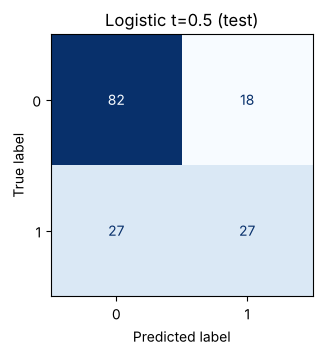

In [4]:
logit = make_pipe(LogisticRegression(max_iter=5000), X_train)
logit.fit(X_train, y_train)
rows = [evaluate_holdout("Majority baseline", DummyClassifier(strategy="most_frequent"), X_train, y_train, X_test, y_test),
        evaluate_holdout("Logistic Regression (t=0.5)", logit, X_train, y_train, X_test, y_test, settings=f"scale={SCALE}")]
print("── hold-out (test) ──"); ht = results_table(rows)
cv = get_cv()
print("── 5-fold CV ──")
ct = results_table([evaluate("Majority baseline", DummyClassifier(strategy="most_frequent"), X, y, cv),
                    evaluate("Logistic Regression", make_pipe(LogisticRegression(max_iter=5000), X), X, y, cv)])
say_compare(ct, "f1", "Majority baseline")
show_cm(y_test, logit.predict(X_test), "Logistic t=0.5 (test)")

## §3 Coefficients → Odds ratio (ตีความ)
- $b > 0$ → x เพิ่ม โอกาสเป็นคลาส 1 เพิ่ม · $b < 0$ → ลด
- **odds ratio** $= e^{b}$: x เพิ่ม 1 หน่วย odds ของคลาส 1 **คูณด้วย** $e^b$ (เช่น 1.04 = เพิ่ม 4%)
- ตาราง 1 = หน่วยเดิม (ไม่ scale, ไม่ regularize) → ตีความต่อ "1 หน่วย" · ตาราง 2 = standardized → เทียบความสำคัญ (ต่อ 1 SD)

,coef (หน่วยเดิม),odds ratio e^b,% เปลี่ยนของ odds ต่อ 1 หน่วย,coef (standardized),odds ratio ต่อ 1 SD
glucose,0.0403,1.0411,4.1080,1.2069,3.3431
bmi,0.1035,1.1091,10.9072,0.7056,2.0250
pregnancies,0.1165,1.1235,12.3537,0.3860,1.4711
pedigree,0.7166,2.0474,104.7381,0.2367,1.2671
age,0.0124,1.0125,1.2473,0.1459,1.1571
insulin,-0.0010,0.9990,-0.0967,-0.0761,0.9268
blood_pressure,-0.0041,0.9959,-0.4128,-0.0504,0.9508
skin_thickness,0.0024,1.0024,0.2420,0.0218,1.0220


logit(p) = ln(p/(1-p)) = -9.9738 + 0.1165×pregnancies + 0.0403×glucose - 0.0041×blood_pressure + 0.0024×skin_thickness - 0.0010×insulin + 0.1035×bmi + 0.7166×pedigree + 0.0124×age
✍️ glucose: เพิ่ม 1 หน่วย → odds ของ diabetes=1 คูณ 1.0411 (+4.11%) โดยตัวแปรอื่นคงที่
✍️ bmi: เพิ่ม 1 หน่วย → odds ของ diabetes=1 คูณ 1.1091 (+10.91%) โดยตัวแปรอื่นคงที่
✍️ pregnancies: เพิ่ม 1 หน่วย → odds ของ diabetes=1 คูณ 1.1235 (+12.35%) โดยตัวแปรอื่นคงที่


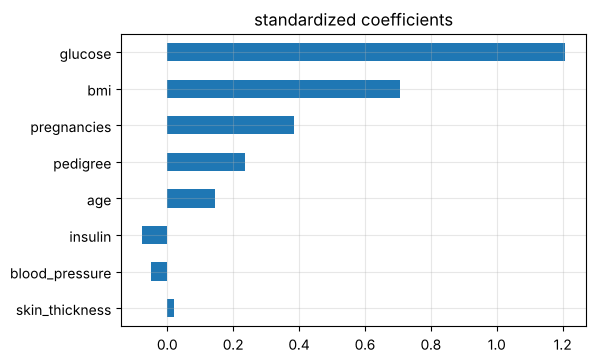

In [5]:
raw = Pipeline([("prep", build_prep(X_train, scale=None)), ("model", LogisticRegression(C=1e6, max_iter=20000))]).fit(X_train, y_train)
names = raw.named_steps["prep"].get_feature_names_out()
b_raw = raw.named_steps["model"].coef_[0]
std = Pipeline([("prep", build_prep(X_train, scale="standard")), ("model", LogisticRegression(C=1e6, max_iter=20000))]).fit(X_train, y_train)
b_std = std.named_steps["model"].coef_[0]
coef = pd.DataFrame({"coef (หน่วยเดิม)": b_raw, "odds ratio e^b": np.exp(b_raw),
                     "% เปลี่ยนของ odds ต่อ 1 หน่วย": (np.exp(b_raw) - 1) * 100,
                     "coef (standardized)": b_std, "odds ratio ต่อ 1 SD": np.exp(b_std)}, index=names)
coef = coef.reindex(coef["coef (standardized)"].abs().sort_values(ascending=False).index)
display(coef)
b0 = raw.named_steps["model"].intercept_[0]
print("logit(p) = ln(p/(1-p)) = " + f"{b0:.4f} " + " ".join(f"{'+' if v >= 0 else '-'} {abs(v):.4f}×{k}" for k, v in zip(names, b_raw)))
for k in coef.index[:3]:
    r = coef.loc[k]
    print(f"✍️ {k}: เพิ่ม 1 หน่วย → odds ของ {TARGET}={POS_LABEL} คูณ {r['odds ratio e^b']:.4f} ({r['% เปลี่ยนของ odds ต่อ 1 หน่วย']:+.2f}%) โดยตัวแปรอื่นคงที่")
coef["coef (standardized)"].plot(kind="barh", figsize=(6, 0.35 * len(coef) + 1), title="standardized coefficients"); plt.gca().invert_yaxis(); plt.show()

**✍️ คำตอบ §3:** ตัวแปรที่มีผลมากสุดคือ … (coef มาตรฐาน …) · `…` เพิ่ม 1 หน่วย odds ของคลาส 1 เพิ่มขึ้น … เท่า (…%) · `…` มี coef ลบ → ลดโอกาส

## §4 คำนวณความน่าจะเป็นด้วยมือ (แถวแรกของ test) — ตรวจกับ predict_proba

ค่าแถวแรก: {'pregnancies': 7.0, 'glucose': 159.0, 'blood_pressure': 64.0, 'skin_thickness': 29.0, 'insulin': 125.0, 'bmi': 27.4, 'pedigree': 0.294, 'age': 40.0}
z = b0 + Σ b·x = 0.4702  →  p = 1/(1+e^(-z)) = 0.6154
predict_proba = 0.6154 → ทาย 1 ที่ t=0.5 / 1 ที่ t=0.3 | ค่าจริง 0


,actual,P(1),pred t=0.5,pred t=0.3
0,0,0.6097,1,1
1,0,0.1183,0,0
2,0,0.2934,0,0
3,1,0.2508,0,0
4,0,0.0335,0,0
5,0,0.1685,0,0
6,1,0.4881,0,1
7,1,0.9237,1,1
8,0,0.0814,0,0
9,0,0.8386,1,1


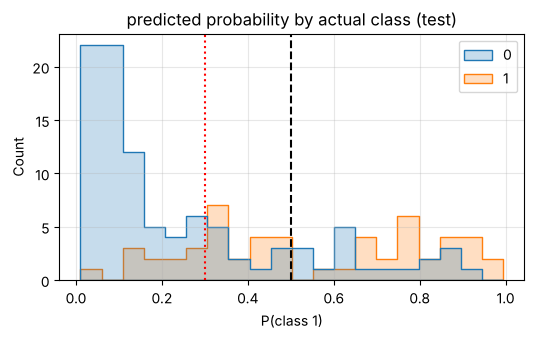

In [6]:
x0 = raw.named_steps["prep"].transform(X_test.iloc[[0]])[0]
z = b0 + float(np.dot(b_raw, x0))
p = 1 / (1 + np.exp(-z))
print("ค่าแถวแรก:", {n: round(float(v), 3) for n, v in zip(names, x0)})
print(f"z = b0 + Σ b·x = {z:.4f}  →  p = 1/(1+e^(-z)) = {p:.4f}")
print(f"predict_proba = {raw.predict_proba(X_test.iloc[[0]])[0, 1]:.4f} → ทาย {int(p >= 0.5)} ที่ t=0.5 / {int(p >= THRESHOLD)} ที่ t={THRESHOLD} | ค่าจริง {y_test.iloc[0]}")
proba_test = logit.predict_proba(X_test)[:, 1]
display(pd.DataFrame({"actual": y_test.values[:10], "P(1)": proba_test[:10], "pred t=0.5": (proba_test[:10] >= .5).astype(int),
                      f"pred t={THRESHOLD}": (proba_test[:10] >= THRESHOLD).astype(int)}))
plt.figure(figsize=(6, 3.2)); sns.histplot(x=proba_test, hue=y_test.values, bins=20, element="step"); plt.axvline(.5, color="k", ls="--"); plt.axvline(THRESHOLD, color="r", ls=":")
plt.xlabel("P(class 1)"); plt.title("predicted probability by actual class (test)"); plt.show()

## §5 Threshold — ตาราง confusion matrix + metrics ทุก threshold ⭐
ลด threshold → ทาย 1 ง่ายขึ้น → **recall ↑ precision ↓** (FN ↓ FP ↑)

,threshold,TP,FP,FN,TN,accuracy,precision,recall,f1
0,0.1000,53,60,1,40,0.6039,0.4690,0.9815,0.6347
1,0.2000,48,39,6,61,0.7078,0.5517,0.8889,0.6809
2,0.3000,43,29,11,71,0.7403,0.5972,0.7963,0.6825
3,0.4000,35,22,19,78,0.7338,0.6140,0.6481,0.6306
4,0.5000,27,18,27,82,0.7078,0.6000,0.5000,0.5455
5,0.6000,25,14,29,86,0.7208,0.6410,0.4630,0.5376
6,0.7000,20,8,34,92,0.7273,0.7143,0.3704,0.4878
7,0.8000,12,6,42,94,0.6883,0.6667,0.2222,0.3333
8,0.9000,5,1,49,99,0.6753,0.8333,0.0926,0.1667


✍️ ลด threshold 0.5 → 0.3: recall 0.5000 → 0.7963 · precision 0.6000 → 0.5972 · F1 0.5455 → 0.6825 · FN 27 → 11 · FP 18 → 29
✍️ threshold ที่ F1 สูงสุด = 0.3 (F1 0.6825)
===== threshold 0.5 =====


,pred 0,pred 1
actual 0,82,18
actual 1,27,27


TN=82  FP=18  FN=27  TP=27
              precision    recall  f1-score   support

           0     0.7523    0.8200    0.7847       100
           1     0.6000    0.5000    0.5455        54

    accuracy                         0.7078       154
   macro avg     0.6761    0.6600    0.6651       154
weighted avg     0.6989    0.7078    0.7008       154



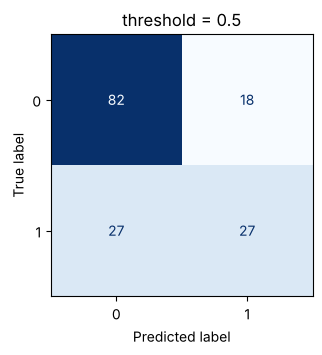

===== threshold 0.3 =====


,pred 0,pred 1
actual 0,71,29
actual 1,11,43


TN=71  FP=29  FN=11  TP=43
              precision    recall  f1-score   support

           0     0.8659    0.7100    0.7802       100
           1     0.5972    0.7963    0.6825        54

    accuracy                         0.7403       154
   macro avg     0.7315    0.7531    0.7314       154
weighted avg     0.7717    0.7403    0.7460       154



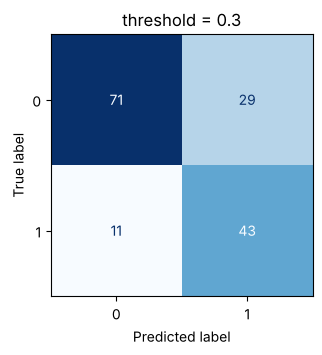

In [7]:
# ใช้ความน่าจะเป็นจาก CV (ทุกแถวถูกทำนายตอนอยู่ใน validation) → เสถียรกว่า test ชุดเดียว · เปลี่ยนเป็น proba_test/y_test ได้ถ้าโจทย์ใช้ hold-out
SOURCE = "holdout"     # ✏️ "holdout" = ใช้ test set · "cv" = cross_val_predict ทั้งชุด
if SOURCE == "cv":
    yy, pp = y, cross_val_predict(make_pipe(LogisticRegression(max_iter=5000), X), X, y, cv=cv, method="predict_proba")[:, 1]
else:
    yy, pp = y_test, proba_test
trows = []
for t in sorted(set(THRESHOLDS + [THRESHOLD, 0.5])):
    pr = (pp >= t).astype(int); tn, fp, fn, tp = confusion_matrix(yy, pr, labels=[0, 1]).ravel()
    trows.append({"threshold": t, "TP": tp, "FP": fp, "FN": fn, "TN": tn, "accuracy": accuracy_score(yy, pr),
                  "precision": precision_score(yy, pr, zero_division=0), "recall": recall_score(yy, pr), "f1": f1_score(yy, pr)})
tt = results_table(trows)
a, b = tt.set_index("threshold").loc[0.5], tt.set_index("threshold").loc[THRESHOLD]
print(f"✍️ ลด threshold 0.5 → {THRESHOLD}: recall {a.recall:.4f} → {b.recall:.4f} · precision {a.precision:.4f} → {b.precision:.4f} · "
      f"F1 {a.f1:.4f} → {b.f1:.4f} · FN {int(a.FN)} → {int(b.FN)} · FP {int(a.FP)} → {int(b.FP)}")
best = tt.loc[tt.f1.idxmax()]; print(f"✍️ threshold ที่ F1 สูงสุด = {best.threshold} (F1 {best.f1:.4f})")
for t in [0.5, THRESHOLD]:
    print(f"===== threshold {t} ====="); show_cm(yy, (pp >= t).astype(int), f"threshold = {t}")

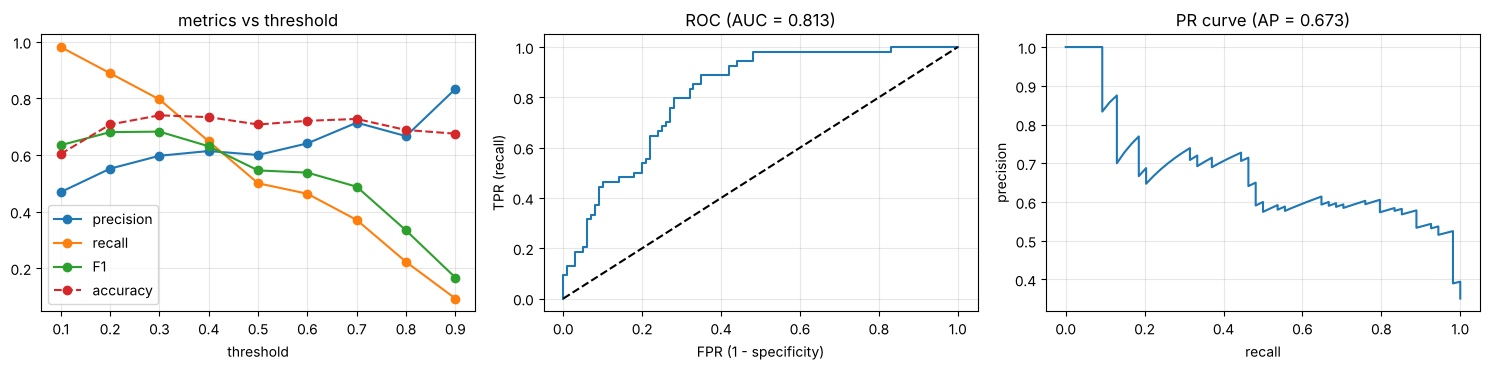

✍️ AUC = 0.8130 → โอกาสที่โมเดลให้คะแนนตัวอย่างคลาส 1 สูงกว่าคลาส 0 ที่สุ่มมา = 81.3% (0.5 = เดาสุ่ม)


In [8]:
fpr, tpr, thr_roc = roc_curve(yy, pp)
prec, rec, _ = precision_recall_curve(yy, pp)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].plot(tt.threshold, tt.precision, "o-", label="precision"); ax[0].plot(tt.threshold, tt.recall, "o-", label="recall")
ax[0].plot(tt.threshold, tt.f1, "o-", label="F1"); ax[0].plot(tt.threshold, tt.accuracy, "o--", label="accuracy"); ax[0].legend(); ax[0].set(xlabel="threshold", title="metrics vs threshold")
ax[1].plot(fpr, tpr); ax[1].plot([0, 1], [0, 1], "k--"); ax[1].set(xlabel="FPR (1 - specificity)", ylabel="TPR (recall)", title=f"ROC (AUC = {roc_auc_score(yy, pp):.3f})")
ax[2].plot(rec, prec); ax[2].set(xlabel="recall", ylabel="precision", title=f"PR curve (AP = {average_precision_score(yy, pp):.3f})")
plt.tight_layout(); plt.show()
print(f"✍️ AUC = {roc_auc_score(yy, pp):.4f} → โอกาสที่โมเดลให้คะแนนตัวอย่างคลาส 1 สูงกว่าคลาส 0 ที่สุ่มมา = {roc_auc_score(yy, pp):.1%} (0.5 = เดาสุ่ม)")

**✍️ คำตอบ §5:** ที่ threshold 0.5 recall … precision … · ลดเป็น … recall เพิ่มเป็น … precision ลดเป็น … · ถ้าการพลาดผู้ป่วยจริง (FN) แพงกว่า → เลือก threshold ต่ำ

## §6 Tune C (regularization) + เทียบก่อน/หลัง (CV)

In [9]:
grid = GridSearchCV(make_pipe(LogisticRegression(max_iter=5000), X),
                    {"model__C": [0.001, 0.01, 0.1, 1, 10, 100], "model__class_weight": [None, "balanced"]},
                    cv=cv, scoring=cls_scoring(y), refit="f1").fit(X, y)
display(top_k(grid, 6))
results_table([evaluate("Majority baseline", DummyClassifier(), X, y, cv),
               evaluate("Logistic default (C=1)", make_pipe(LogisticRegression(max_iter=5000), X), X, y, cv),
               evaluate("Logistic tuned", grid.best_estimator_, X, y, cv, str(grid.best_params_))])
print("✍️ C เล็ก = regularize แรง (coef หดเข้า 0) · class_weight='balanced' = ให้น้ำหนักคลาสส่วนน้อย → recall ↑")

,param_model__C,param_model__class_weight,mean_test_accuracy,mean_test_precision,mean_test_recall,mean_test_f1
0,0.1000,balanced,0.7473,0.6252,0.7275,0.6695
1,1.0000,balanced,0.7473,0.6234,0.7274,0.6688
2,10.0000,balanced,0.7473,0.6240,0.7237,0.6675
3,100.0000,balanced,0.7473,0.6240,0.7237,0.6675
4,0.0100,balanced,0.7330,0.6083,0.6902,0.6447
5,10.0000,NaN,0.7760,0.7313,0.5785,0.6428


,model,settings,accuracy,precision,recall,f1,f1_std
0,Majority baseline,,0.6510,0.0000,0.0000,0.0000,0.0000
1,Logistic default (C=1),,0.7721,0.7261,0.5711,0.6358,0.0210
2,Logistic tuned,"{'model__C': 0.1, 'model__class_weight': 'bala...",0.7473,0.6252,0.7275,0.6695,0.0458


✍️ C เล็ก = regularize แรง (coef หดเข้า 0) · class_weight='balanced' = ให้น้ำหนักคลาสส่วนน้อย → recall ↑


## §7 ทำนายข้อมูลใหม่ (probability + คำตัดสินที่ threshold 0.5 และ THRESHOLD)

In [10]:
if NEW_DATA is not None:
    nd = align_new(new_data(NEW_DATA), X)
    pn = logit.predict_proba(nd)[:, 1]
    out = nd.copy(); out["P(1)"] = pn; out["pred t=0.5"] = (pn >= .5).astype(int); out[f"pred t={THRESHOLD}"] = (pn >= THRESHOLD).astype(int)
    display(out)
    print(f"✍️ ข้อมูลใหม่มีความน่าจะเป็นเป็น {TARGET}={POS_LABEL} = {pn[0]:.4f} → ที่ threshold 0.5 ทาย {int(pn[0] >= .5)}, ที่ {THRESHOLD} ทาย {int(pn[0] >= THRESHOLD)}")

,pregnancies,glucose,blood_pressure,skin_thickness,insulin,bmi,pedigree,age,P(1),pred t=0.5,pred t=0.3
0,2,150,70,30,100,32.0000,0.5000,45,0.5490,1,1


✍️ ข้อมูลใหม่มีความน่าจะเป็นเป็น diabetes=1 = 0.5490 → ที่ threshold 0.5 ทาย 1, ที่ 0.3 ทาย 1
